# Decision trees: five-fold geographic cross-validation

This notebook compares five sets of catalog and waveform features for classifying earthquakes and explosions in the Pacific Northwest. Each saved geographic fold is held out once while the other four train the models.

Place this notebook and `pnw_training_corrected.csv` in the same folder, then run the cells from top to bottom.


## 1. Data and folds

The catalog labels earthquakes as `0` and explosions as `1`. We use the existing `geographic_fold` assignments, numbered 1 through 5. After five runs, every event has one prediction from a model trained without its fold. These are **out-of-fold (OOF) predictions**.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    average_precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, confusion_matrix,
)

DATA_PATH = Path("pnw_training_corrected.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place pnw_training_corrected.csv beside this notebook and run from that folder.")
df = pd.read_csv(DATA_PATH)
assert df.shape == (38579, 22), "Expected the corrected PNW dataset."
assert df["event_id"].is_unique
assert set(df["label"]) == {0, 1}
assert set(df["geographic_fold"]) == {1, 2, 3, 4, 5}
FOLDS = [1, 2, 3, 4, 5]


In [2]:
PAPER = "#FAF8F3"
INK = "#29383B"
MUTED = "#687471"
RULE = "#D9DED6"
SAGE = "#4F7569"
CLAY = "#A5664E"

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "figure.facecolor": PAPER, "axes.facecolor": PAPER,
    "savefig.facecolor": PAPER, "text.color": INK,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": INK,
    "axes.edgecolor": RULE, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "normal",
    "figure.dpi": 120, "savefig.dpi": 200,
})


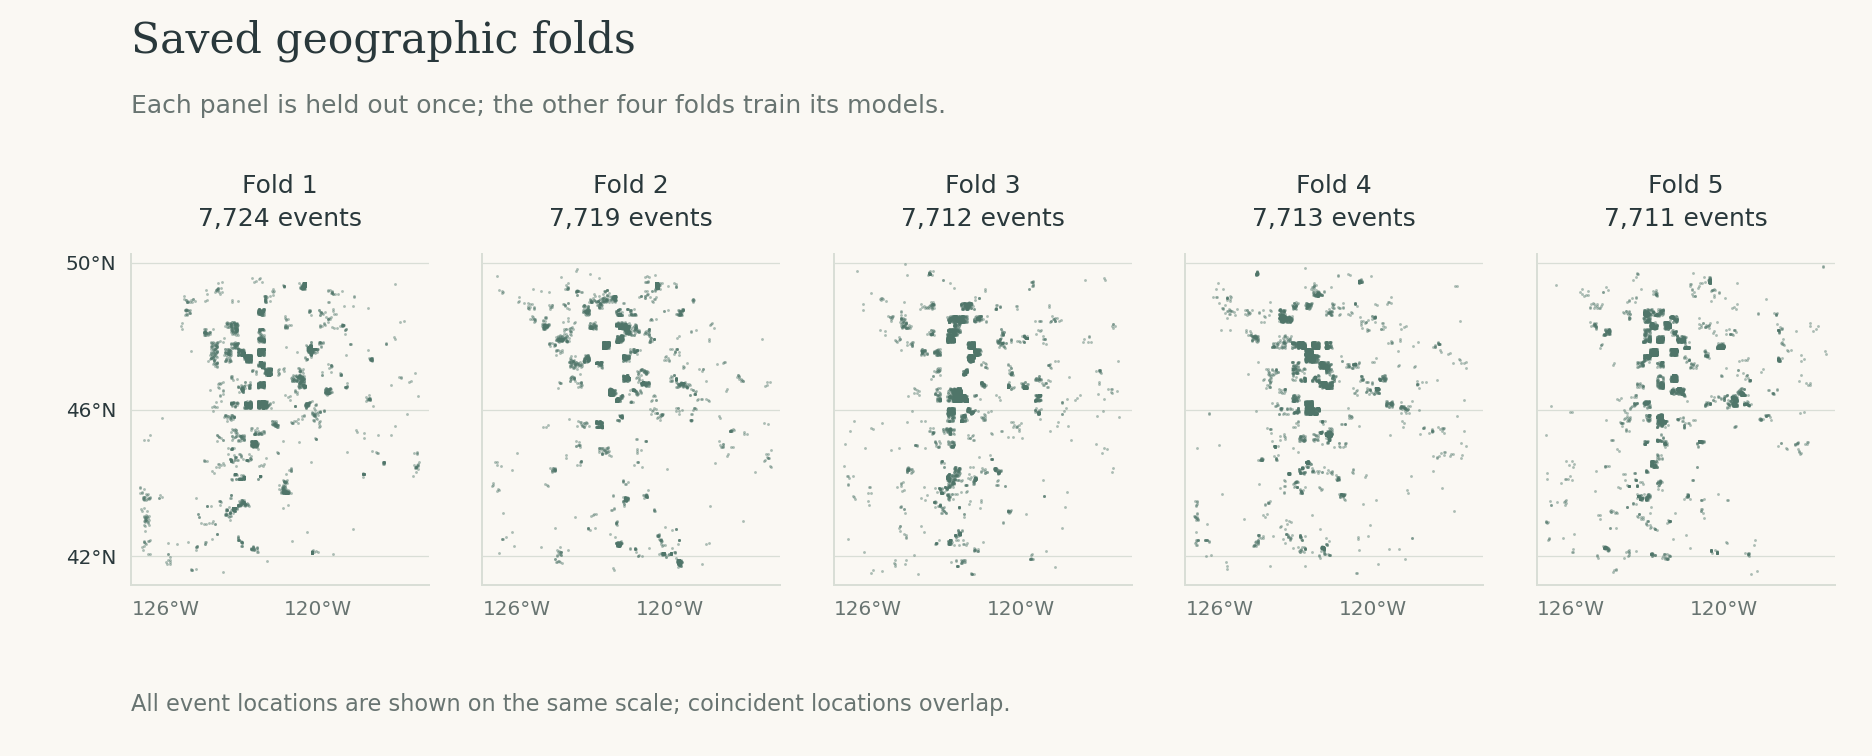

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(10.4, 4.2), sharex=True, sharey=True)
fig.subplots_adjust(left=0.07, right=0.98, bottom=0.19, top=0.70, wspace=0.18)
fig.text(0.07, 0.93, "Saved geographic folds", family="DejaVu Serif", fontsize=17)
fig.text(0.07, 0.85, "Each panel is held out once; the other four folds train its models.", color=MUTED)

for ax, fold in zip(axes, FOLDS):
    events = df[df["geographic_fold"] == fold]
    ax.scatter(events["source_longitude_deg"], events["source_latitude_deg"],
               s=1.3, color=SAGE, alpha=0.46, linewidths=0)
    ax.set_xlim(-127.35, -115.65)
    ax.set_ylim(41.2, 50.25)
    ax.set_aspect(1 / np.cos(np.deg2rad(46)))
    ax.set_xticks([-126, -120])
    ax.set_yticks([42, 46, 50])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{abs(x):.0f}°W"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"{y:.0f}°N"))
    ax.tick_params(length=0, pad=6, labelsize=8)
    ax.grid(axis="y", color=RULE, linewidth=0.5)
    ax.set_axisbelow(True)
    ax.set_title(f"Fold {fold}\n{len(events):,} events", fontsize=10, pad=11, linespacing=1.5)

fig.text(0.07, 0.06, "All event locations are shown on the same scale; coincident locations overlap.",
         fontsize=9, color=MUTED)
plt.show()


The maps' east–west scale is adjusted for latitude 46°N. Training and test events come from separate spatial groups, but no minimum distance is required between those groups. A training event can therefore be close to a test event.


## 2. Features and fixed model settings

Catalog inputs describe location, magnitude, time of day and weekends. Waveform inputs describe signal amplitude, frequency content, component ratios and envelope shape. Catalog depth is an event's recorded depth; tree depth limits the model's decision steps.

Only the columns below are inputs. The waveform-only model contains no catalog variables or depth.


In [4]:
CATALOG = [
    "source_latitude_deg",
    "source_longitude_deg",
    "preferred_source_magnitude",
    "local_hour_sin",
    "local_hour_cos",
    "weekend",
]

WAVEFORM = [
    "cb_crest_factor",
    "cb_spectral_entropy",
    "nb_log10_pz_sh_rms_ratio_4_8hz",
    "nb_log10_sh_sz_rms_ratio_4_8hz",
    "nb_envelope_rise_10_90_s_2_10hz",
    "nb_envelope_excess_kurtosis_2_10hz",
    "nb_log10_psd_power_1_5_over_5_15hz",
]

DEPTH = ["source_depth_km"]
FEATURE_SETS = {
    "Catalog": CATALOG,
    "Catalog + depth": CATALOG + DEPTH,
    "Catalog + waveform": CATALOG + WAVEFORM,
    "Catalog + waveform + depth": CATALOG + WAVEFORM + DEPTH,
    "Waveform only": WAVEFORM,
}

assert np.isfinite(df[CATALOG + WAVEFORM + DEPTH].to_numpy()).all()


We keep the teaching baseline's provisional settings and cutoff, without balancing, resampling or tuning. A tree assigns each test event to a final group, or leaf. Its explosion score is the fraction of training events in that leaf labeled as explosions. We have not checked whether these scores match explosion frequencies on independent data.

The same metric function is used for each fold and for the pooled OOF predictions. Precision is left undefined (`NaN`) when a model flags no events.


In [5]:
MAX_DEPTH = 3
RANDOM_STATE = 42
THRESHOLD = 0.5

def evaluate(labels, scores):
    predicted = (scores >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if tp + fp else np.nan
    return {
        "average_precision": average_precision_score(labels, scores),
        "precision": precision,
        "recall": recall_score(labels, predicted, zero_division=0),
        "f1": f1_score(labels, predicted, zero_division=0),
        "roc_auc": roc_auc_score(labels, scores),
        "brier_score": brier_score_loss(labels, scores),
        "true_negative": int(tn), "false_positive": int(fp),
        "false_negative": int(fn), "true_positive": int(tp),
    }

fold_rows = []
oof_rows = []

for held_out in FOLDS:
    test = df["geographic_fold"] == held_out
    train = ~test
    y_train = df.loc[train, "label"]
    y_test = df.loc[test, "label"]
    assert set(y_train) == {0, 1} and set(y_test) == {0, 1}

    for name, columns in FEATURE_SETS.items():
        tree = DecisionTreeClassifier(
            max_depth=MAX_DEPTH, random_state=RANDOM_STATE,
            criterion="gini", class_weight=None,
        )
        tree.fit(df.loc[train, columns], y_train)
        positive_column = list(tree.classes_).index(1)
        scores = tree.predict_proba(df.loc[test, columns])[:, positive_column]

        row = evaluate(y_test, scores)
        row["model"] = name
        row["test_fold"] = held_out
        fold_rows.append(row)
        oof_rows.append(pd.DataFrame({
            "model": name,
            "event_id": df.loc[test, "event_id"].to_numpy(),
            "test_fold": held_out,
            "actual_label": y_test.to_numpy(),
            "explosion_score": scores,
            "predicted_label": (scores >= THRESHOLD).astype(int),
        }))

fold_results = pd.DataFrame(fold_rows)
oof_predictions = pd.concat(oof_rows, ignore_index=True)
assert len(fold_results) == 5 * len(FEATURE_SETS)
assert not oof_predictions.duplicated(["model", "event_id"]).any()
assert oof_predictions.groupby("model").size().eq(len(df)).all()

pooled_rows = []
for name in FEATURE_SETS:
    events = oof_predictions[oof_predictions["model"] == name]
    row = evaluate(events["actual_label"], events["explosion_score"])
    row["model"] = name
    pooled_rows.append(row)
pooled_results = pd.DataFrame(pooled_rows).set_index("model")


## 3. Average precision across folds

Average precision (AP) summarizes the tradeoff between detecting explosions and avoiding false flags across score cutoffs. Higher AP is better. We calculate average precision using scikit-learn.

The mean gives each fold equal weight. The standard deviation (SD, calculated with `ddof=1`) describes variation among the five fold scores, not a confidence interval. The training sets overlap.


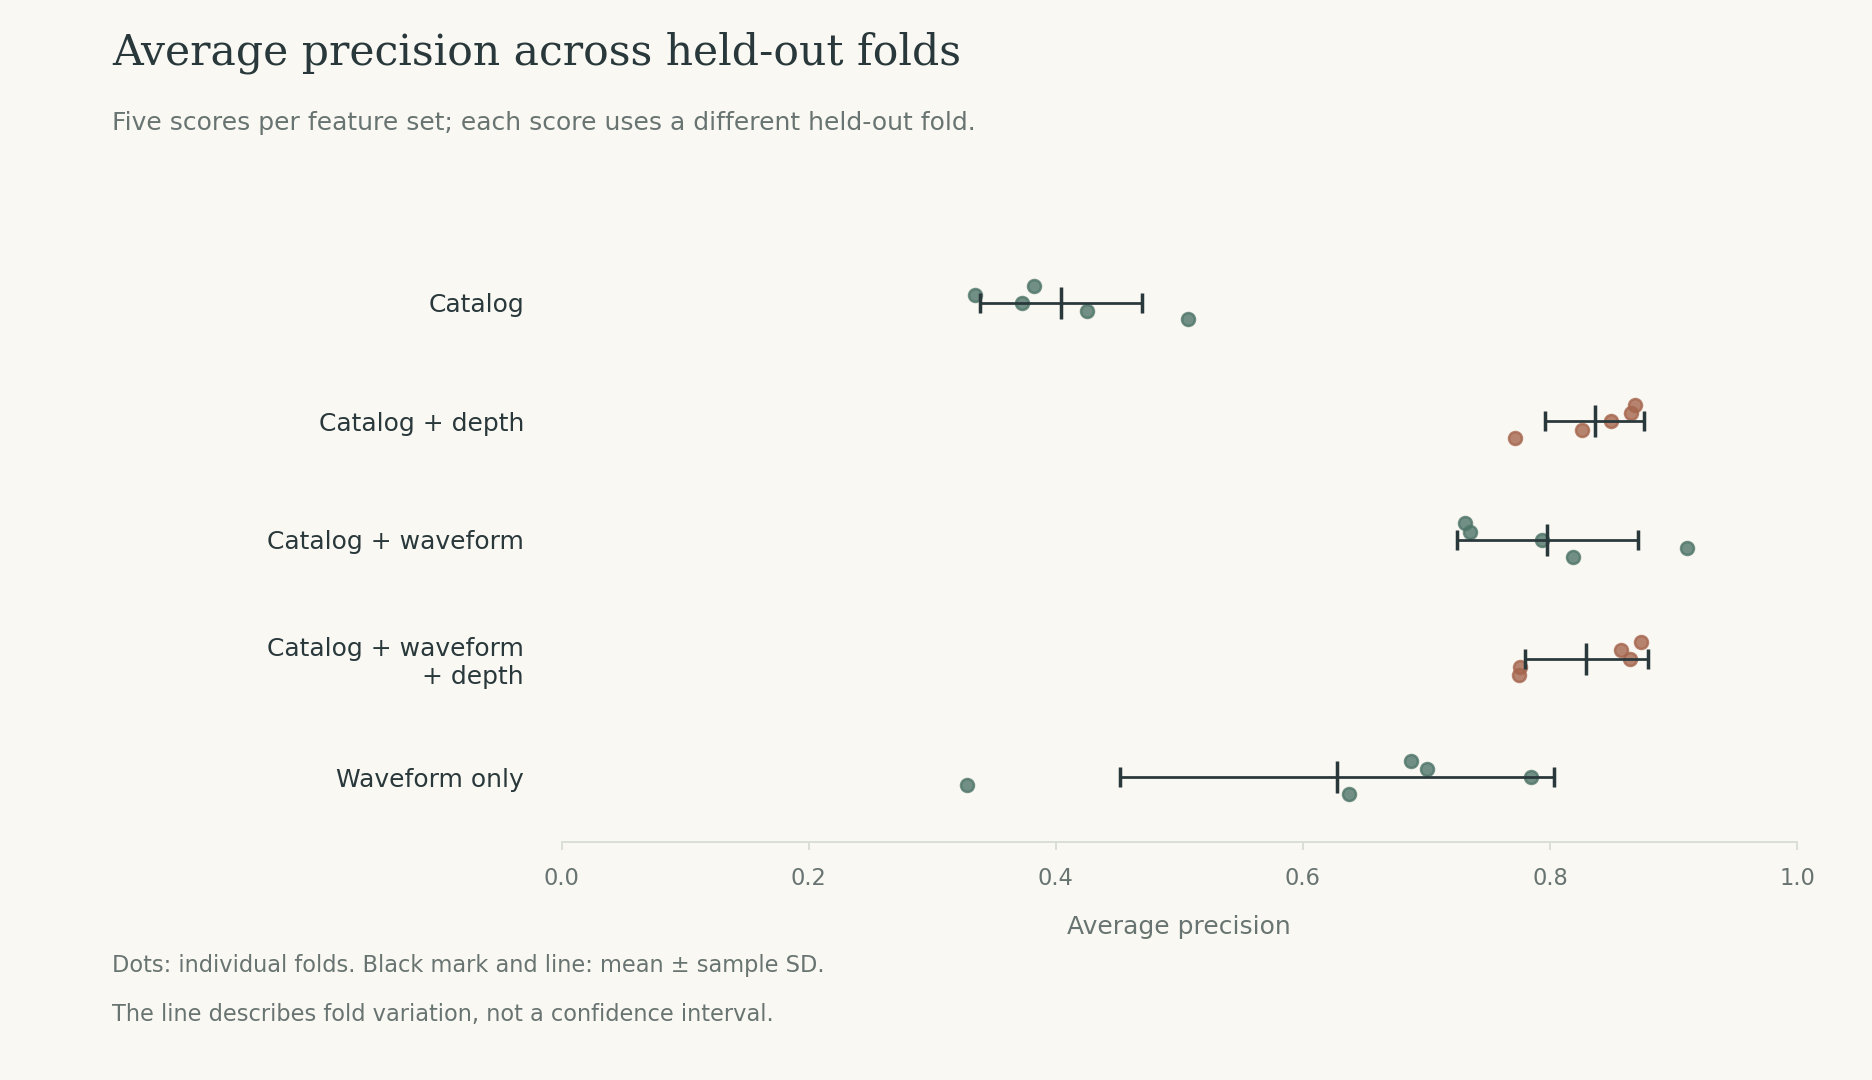

In [6]:
ap = fold_results.pivot(index="model", columns="test_fold", values="average_precision")
ap = ap.reindex(list(FEATURE_SETS))[FOLDS]
ap_mean = ap.mean(axis=1)
ap_sd = ap.std(axis=1, ddof=1)

fig, ax = plt.subplots(figsize=(10.4, 6.0))
fig.subplots_adjust(left=0.30, right=0.96, bottom=0.22, top=0.78)
fig.text(0.06, 0.94, "Average precision across held-out folds", family="DejaVu Serif", fontsize=17)
fig.text(0.06, 0.88, "Five scores per feature set; each score uses a different held-out fold.", color=MUTED)

offsets = np.linspace(-0.14, 0.14, len(FOLDS))
for i, name in enumerate(FEATURE_SETS):
    y = len(FEATURE_SETS) - 1 - i
    color = CLAY if "depth" in name else SAGE
    ax.scatter(ap.loc[name], y + offsets, s=27, color=color, alpha=0.8, zorder=3)
    ax.errorbar(ap_mean[name], y, xerr=ap_sd[name], fmt="|", color=INK,
                markersize=13, markeredgewidth=1.4, capsize=4, linewidth=1.1, zorder=4)
ax.set_xlim(0, 1)
ax.set_ylim(-0.55, 4.55)
ax.set_yticks(range(4, -1, -1), ["Catalog", "Catalog + depth", "Catalog + waveform",
                               "Catalog + waveform\n+ depth", "Waveform only"])
ax.tick_params(axis="y", length=0, pad=15, labelsize=10)
ax.tick_params(axis="x", length=3, color=RULE, pad=7, labelsize=9)
ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.set_xlabel("Average precision", labelpad=10, fontsize=10)
ax.spines["left"].set_visible(False)
fig.text(0.06, 0.10, "Dots: individual folds. Black mark and line: mean ± sample SD.", fontsize=9, color=MUTED)
fig.text(0.06, 0.055, "The line describes fold variation, not a confidence interval.", fontsize=9, color=MUTED)
plt.show()


**Pooled OOF AP** combines all held-out scores before calculating AP. It is different from averaging the five fold APs: it ranks scores from five separately fitted trees, whose calibration has not been checked.


In [7]:
ap_summary = ap.copy()
ap_summary.columns = [f"Fold {fold}" for fold in FOLDS]
ap_summary["Mean"] = ap_mean
ap_summary["SD"] = ap_sd
ap_summary["OOF AP"] = pooled_results["average_precision"]
print(ap_summary.to_string(float_format=lambda x: f"{x:.4f}"))


                            Fold 1  Fold 2  Fold 3  Fold 4  Fold 5   Mean     SD  OOF AP
model                                                                                   
Catalog                     0.5066  0.4253  0.3728  0.3347  0.3820 0.4043 0.0657  0.4262
Catalog + depth             0.7713  0.8259  0.8493  0.8659  0.8686 0.8362 0.0401  0.8275
Catalog + waveform          0.8188  0.9107  0.7934  0.7354  0.7309 0.7978 0.0735  0.7999
Catalog + waveform + depth  0.7745  0.7760  0.8647  0.8578  0.8738 0.8294 0.0497  0.8088
Waveform only               0.6374  0.3282  0.7844  0.7005  0.6874 0.6276 0.1755  0.6274


Catalog + depth has mean AP **0.836**, compared with **0.829** for Catalog + waveform + depth. Waveform-only AP ranges from **0.328 to 0.784** across folds. These are comparisons on the five saved folds, not evidence that the small difference between the two depth models will persist on new data.

Catalog depth may reflect an analyst's earlier judgment about whether an event was an explosion. If that judgment influenced the recorded depth, the model could reuse it. This comparison cannot separate physical depth differences from cataloging decisions.


## 4. Predictions at cutoff 0.5

The plot sums held-out predictions across folds. Each event contributes once per feature set. False positives are catalog earthquakes flagged as explosions; true positives are correctly detected catalog explosions. The two counts use the same scale.


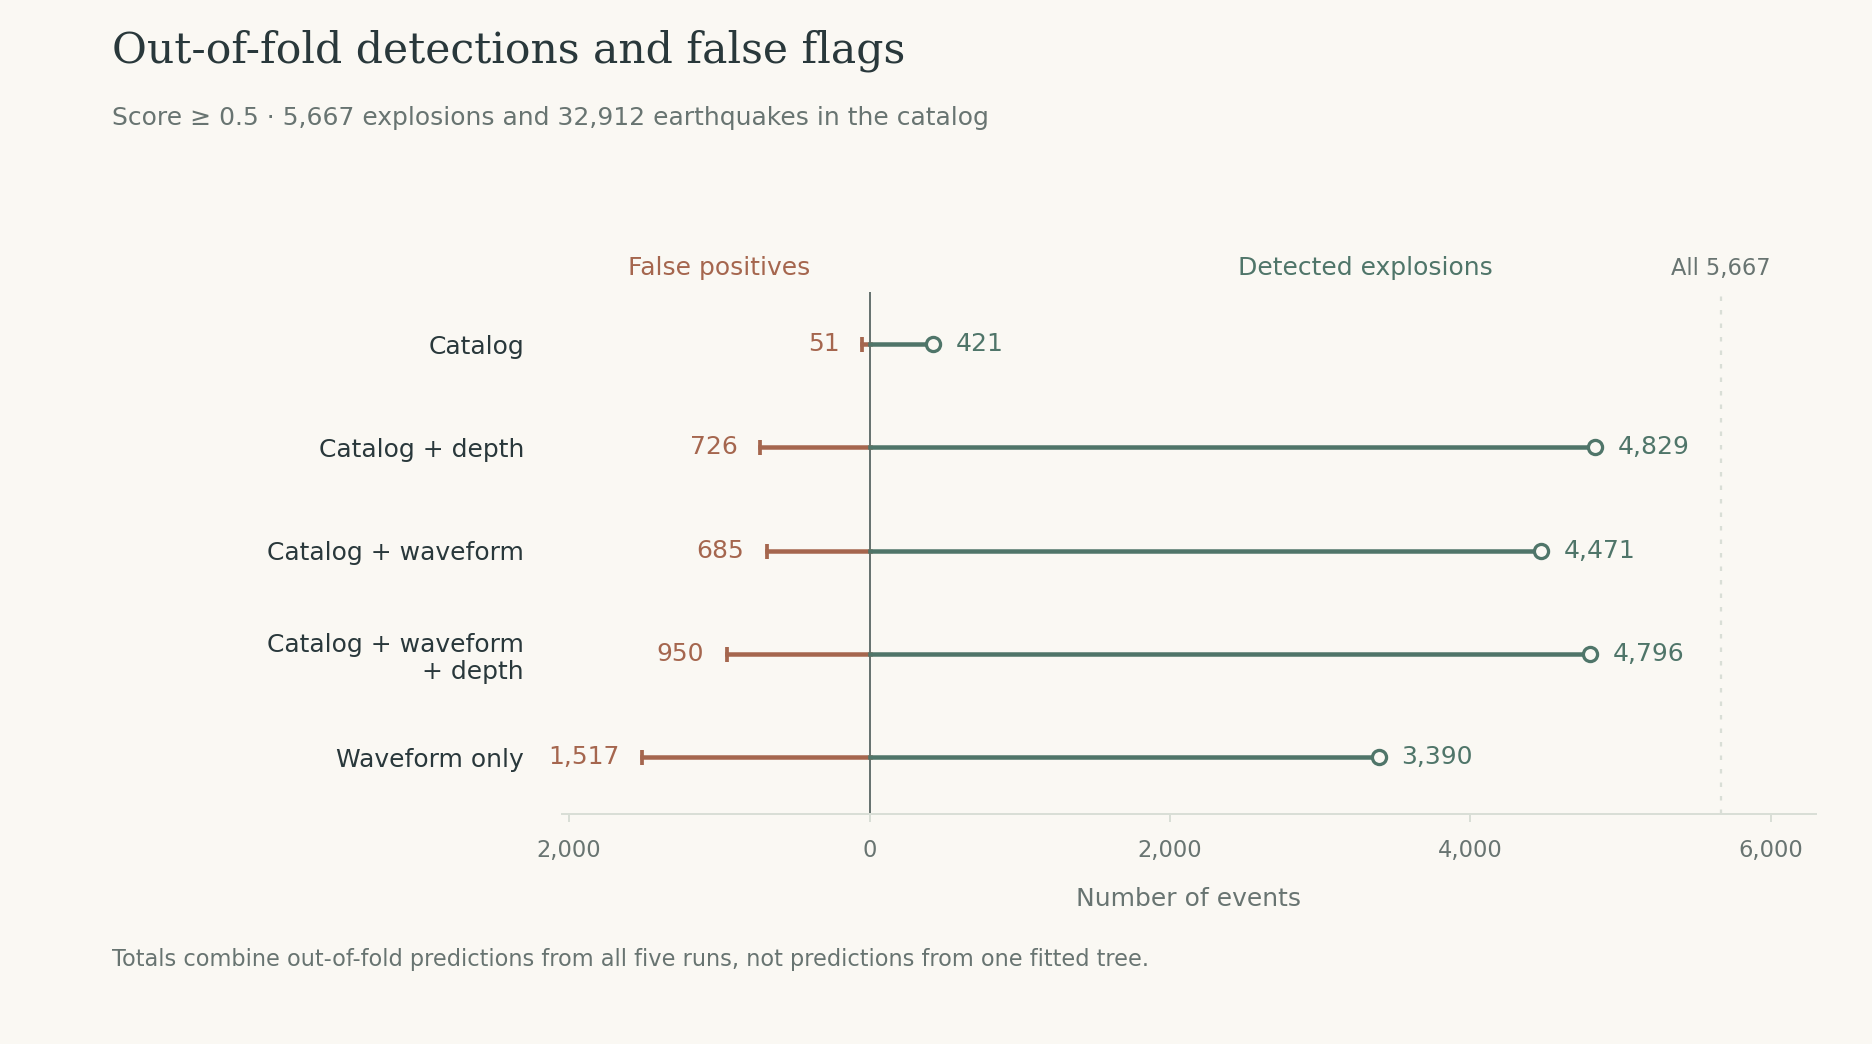

In [8]:
fig, ax = plt.subplots(figsize=(10.4, 5.8))
fig.subplots_adjust(left=0.30, right=0.97, bottom=0.22, top=0.72)
fig.text(0.06, 0.94, "Out-of-fold detections and false flags", family="DejaVu Serif", fontsize=17)
fig.text(0.06, 0.88, "Score ≥ 0.5 · 5,667 explosions and 32,912 earthquakes in the catalog", color=MUTED)

for i, (name, row) in enumerate(pooled_results.iterrows()):
    y = len(FEATURE_SETS) - 1 - i
    ax.plot([-row.false_positive, 0], [y, y], color=CLAY, linewidth=1.8)
    ax.plot([0, row.true_positive], [y, y], color=SAGE, linewidth=1.8)
    ax.scatter(-row.false_positive, y, s=36, marker="|", color=CLAY, zorder=3)
    ax.scatter(row.true_positive, y, s=32, facecolor=PAPER, edgecolor=SAGE, linewidth=1.3, zorder=3)
    ax.annotate(f"{int(row.false_positive):,}", (-row.false_positive, y),
                xytext=(-9, 0), textcoords="offset points", ha="right", va="center", color=CLAY)
    ax.annotate(f"{int(row.true_positive):,}", (row.true_positive, y),
                xytext=(9, 0), textcoords="offset points", ha="left", va="center", color=SAGE)
ax.set_xlim(-2050, 6300)
ax.set_ylim(-0.55, 4.5)
ax.set_yticks(range(4, -1, -1), ["Catalog", "Catalog + depth", "Catalog + waveform",
                               "Catalog + waveform\n+ depth", "Waveform only"])
ax.tick_params(axis="y", length=0, pad=15, labelsize=10)
ax.tick_params(axis="x", length=3, color=RULE, pad=7, labelsize=9)
ax.set_xticks([-2000, 0, 2000, 4000, 6000])
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{abs(x):,.0f}"))
ax.set_xlabel("Number of events", labelpad=10, fontsize=10)
ax.spines["left"].set_visible(False)
ax.axvline(0, color=MUTED, linewidth=0.8, zorder=0)
ax.axvline(int(df["label"].sum()), color=RULE, linestyle=(0, (2, 4)), linewidth=0.9, zorder=0)
ax.text(-1000, 4.67, "False positives", ha="center", color=CLAY, fontsize=10)
ax.text(3300, 4.67, "Detected explosions", ha="center", color=SAGE, fontsize=10)
ax.text(5667, 4.67, "All 5,667", ha="center", color=MUTED, fontsize=9)
fig.text(0.06, 0.075, "Totals combine out-of-fold predictions from all five runs, not predictions from one fitted tree.",
         fontsize=9, color=MUTED)
plt.show()


The following metrics are calculated from the pooled OOF predictions, not averaged across folds.

- **Precision:** the fraction of flags that are catalog explosions.
- **Recall:** the fraction of catalog explosions detected.
- **F1:** combines precision and recall; it is high only when both are high.
- **ROC AUC:** how well scores rank explosions above earthquakes; higher is better.
- **Brier:** mean squared difference between score and catalog label; lower is better.

TN counts correctly classified earthquakes, FP false flags, FN missed explosions and TP detected explosions. The last column lists folds with no positive predictions: precision is undefined there, even when pooled precision is defined. Catalog flags no events in fold 3; its recall and F1 for that fold are zero.


In [9]:
summary = pooled_results[[
    "roc_auc", "brier_score", "precision", "recall", "f1",
    "true_negative", "false_positive", "false_negative", "true_positive",
]].copy()
summary.columns = ["ROC AUC", "Brier", "Precision", "Recall", "F1", "TN", "FP", "FN", "TP"]
no_flag_folds = {}
for name in FEATURE_SETS:
    missing = fold_results[(fold_results["model"] == name) & fold_results["precision"].isna()]
    no_flag_folds[name] = ",".join(missing["test_fold"].astype(str)) or "none"
summary["No-flag folds"] = pd.Series(no_flag_folds)
print(summary.to_string(float_format=lambda x: f"{x:.4f}", na_rep="undefined"))


                            ROC AUC  Brier  Precision  Recall     F1     TN    FP    FN    TP No-flag folds
model                                                                                                      
Catalog                      0.8449 0.0995     0.8919  0.0743 0.1372  32861    51  5246   421             3
Catalog + depth              0.9595 0.0340     0.8693  0.8521 0.8606  32186   726   838  4829          none
Catalog + waveform           0.9266 0.0430     0.8671  0.7890 0.8262  32227   685  1196  4471          none
Catalog + waveform + depth   0.9636 0.0359     0.8347  0.8463 0.8404  31962   950   871  4796          none
Waveform only                0.8825 0.0732     0.6908  0.5982 0.6412  31395  1517  2277  3390          none


These results compare the five fixed feature sets under the saved geographic folds. If the results are used to choose features, model settings or a cutoff, the chosen procedure still needs evaluation on independent data.
